<a href="https://colab.research.google.com/github/samueladian3-cpu/ml-portfolio/blob/main/%5BClustering%5D_Submission_Akhir_BMLP_Samuel_Adian.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Penting**
- Jangan menambahkan import library atau function apa pun, selain yang sudah tersedia pada cell code atau yang diperbolehkan.
- Jangan mengubah atau menambahkan cell text yang sudah disediakan, Anda hanya perlu mengerjakan cell code yang sudah disediakan.
- Pastikan seluruh kriteria memiliki output yang sesuai, karena jika tidak ada output dianggap tidak selesai.
- Pastikan Anda melakukan Run All sebelum mengirimkan submission untuk memastikan seluruh cell berjalan dengan baik.
- Pastikan Anda menggunakan variabel df dari awal sampai akhir dan tidak diperbolehkan mengganti nama variabel tersebut.

# **1. Import Library**
Pada tahap ini, kita mengimpor semua pustaka Python yang dibutuhkan untuk analisis data, preprocessing, clustering, dan visualisasi.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from yellowbrick.cluster import KElbowVisualizer

import joblib
import warnings
warnings.filterwarnings('ignore')

# **2. Memuat Dataset**
Memuat dataset Bank Transaction dari file CSV ke dalam DataFrame Pandas.

In [ ]:
from google.colab import files
import io

# Upload data
uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))
  df = pd.read_csv(io.StringIO(uploaded[fn].decode('utf-8')))

# Tampilkan 5 baris pertama dengan function head
df.head()

Saving bank_transactions_data_edited.csv to bank_transactions_data_edited.csv
User uploaded file "bank_transactions_data_edited.csv" with length 362918 bytes


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 08:06:39


In [ ]:
# Tinjau jumlah baris kolom dan jenis data dalam dataset dengan info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   TransactionDate          2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [ ]:
# Menampilkan statistik deskriptif dataset dengan menjalankan describe
df.describe(include='all')

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
count,2508,2516,2511.000000,2509,2507,2507,2507,2517,2514,2510,2519.000000,2514,2511.000000,2516.000000,2510.000000,2513
unique,2484,495,NaN,2485,2,43,681,591,100,3,NaN,4,NaN,NaN,NaN,360
top,TX001748,AC00362,NaN,2023-10-20 17:53:13,Debit,Fort Worth,D000573,200.136.146.93,M026,Branch,NaN,Student,NaN,NaN,NaN,2024-11-04 08:09:17
freq,2,12,NaN,2,1942,71,9,12,46,868,NaN,657,NaN,NaN,NaN,18
mean,NaN,NaN,297.656468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44.678444,NaN,119.422939,1.121622,5113.438124,NaN
std,NaN,NaN,292.230367,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.837359,NaN,70.078513,0.594469,3897.975861,NaN
min,NaN,NaN,0.260000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.000000,NaN,10.000000,1.000000,101.250000,NaN
25%,NaN,NaN,81.310000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.000000,NaN,63.000000,1.000000,1504.727500,NaN
50%,NaN,NaN,211.360000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.000000,NaN,112.000000,1.000000,4734.110000,NaN
75%,NaN,NaN,413.105000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.000000,NaN,161.000000,1.000000,7672.687500,NaN


## **Penilaian (Opsional) - Skilled: Korelasi dan Histogram**

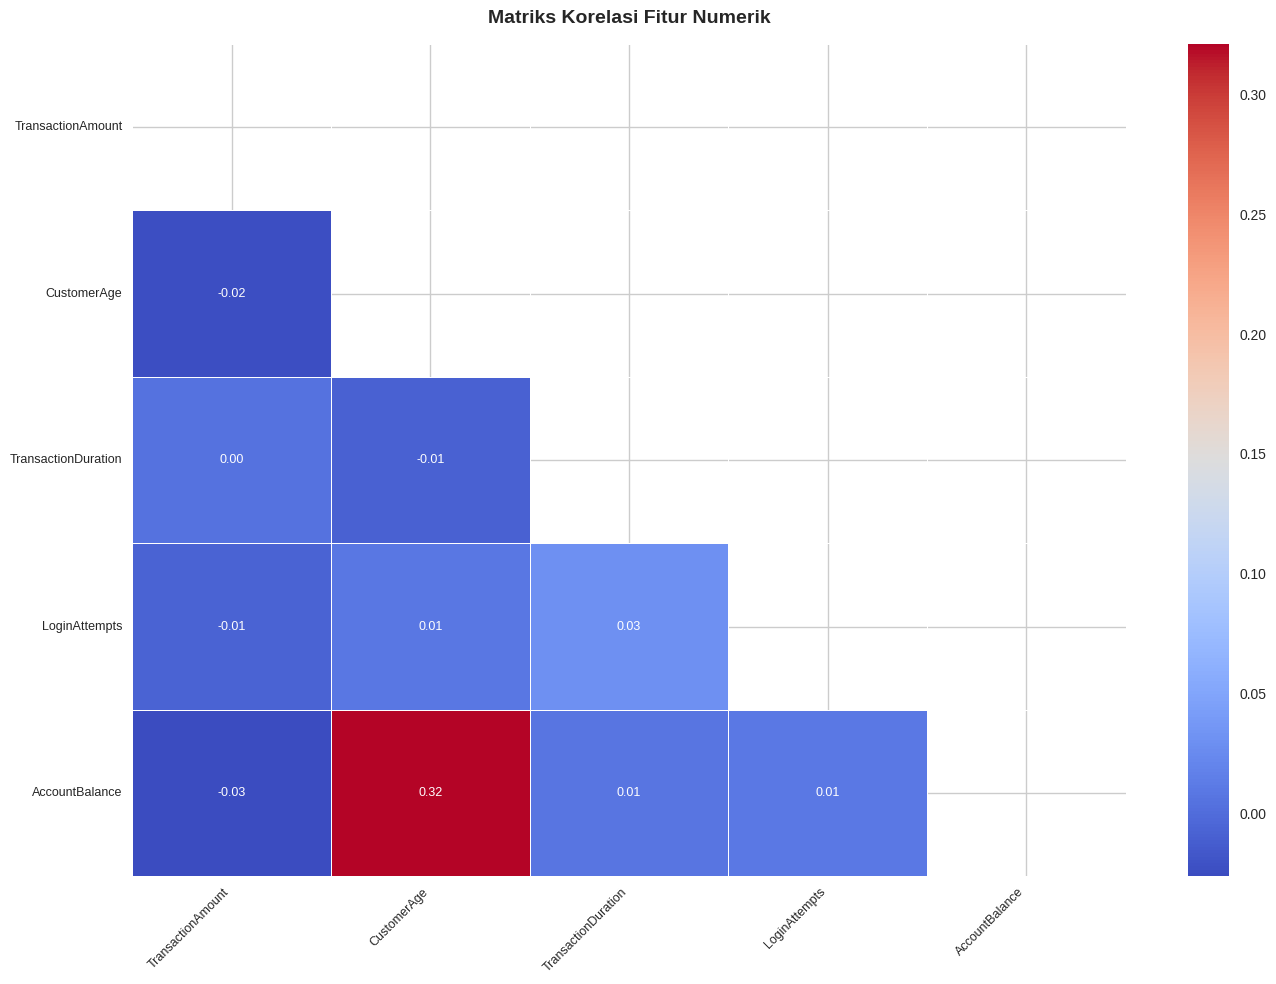

In [ ]:
# Menampilkan korelasi antar fitur (Opsional Skilled 1)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(14, 10))
corr_matrix = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    annot_kws={'size': 9}
)
plt.title('Matriks Korelasi Fitur Numerik', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

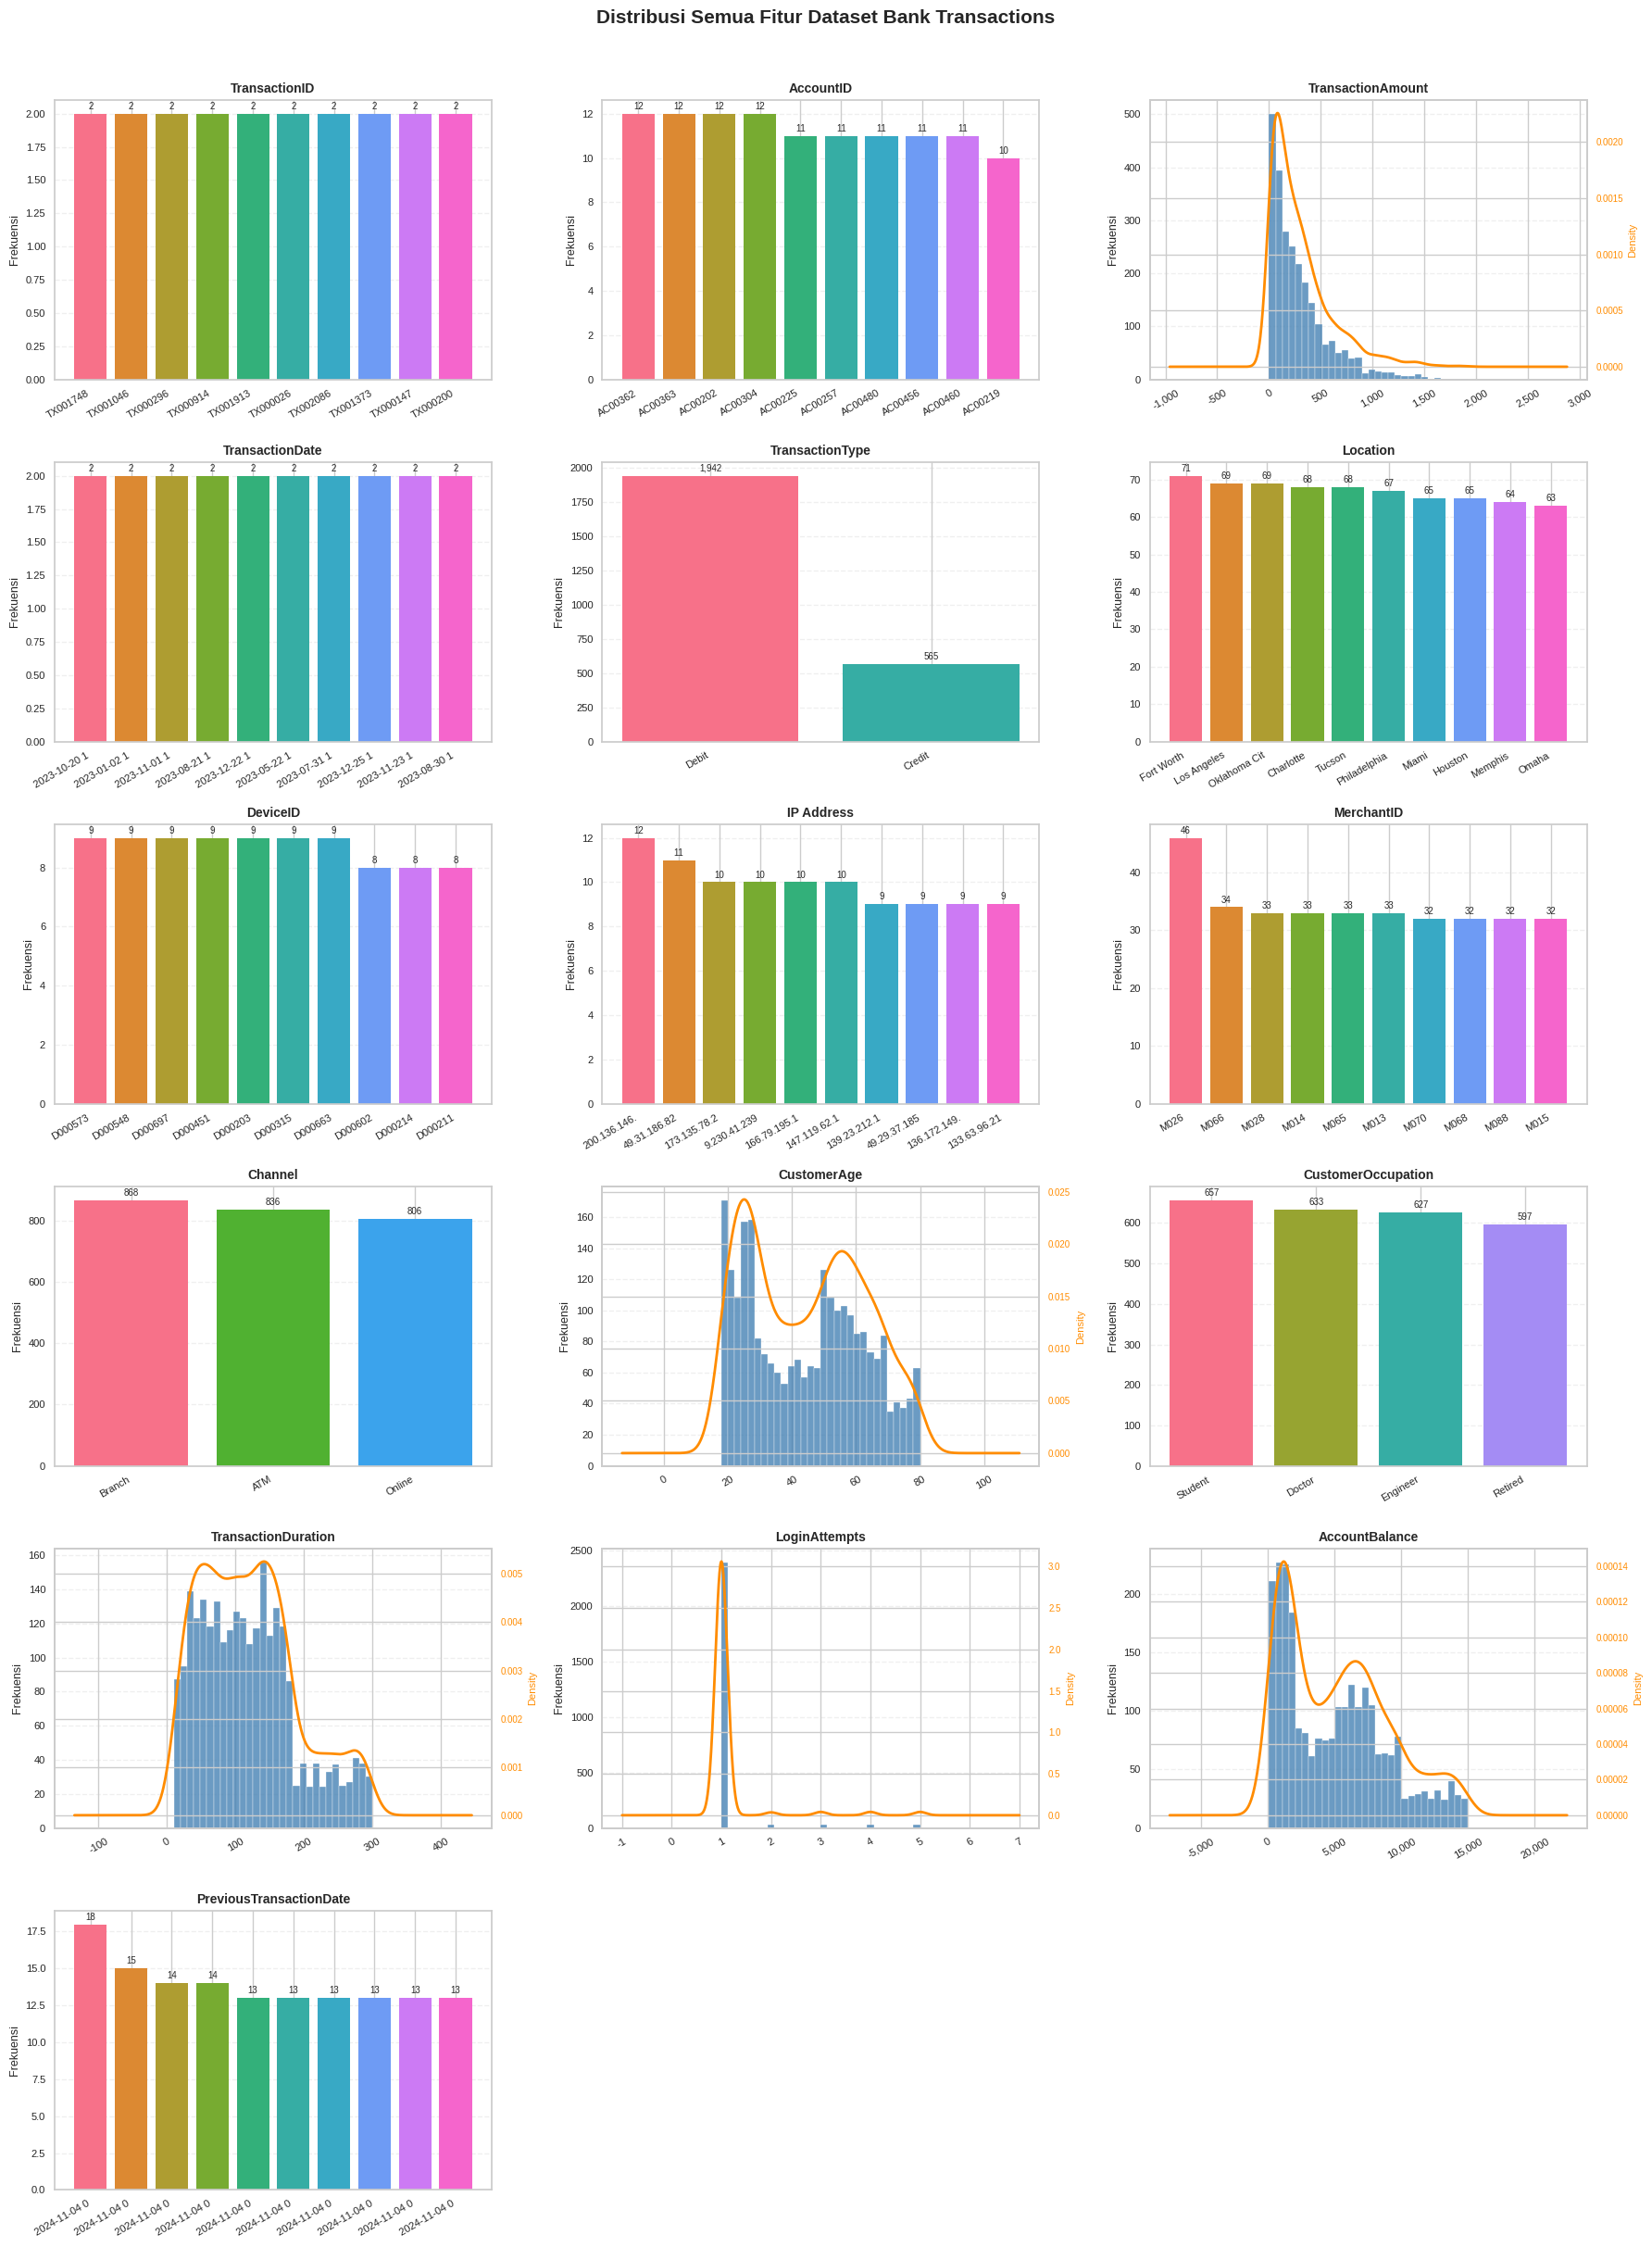

In [ ]:
# Menampilkan histogram untuk semua kolom dalam dataset (Opsional Skilled 1)
# Visualisasi yang lebih informatif (Opsional Advanced 1)

all_cols = df.columns.tolist()
n_cols = 3
n_rows = (len(all_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(all_cols):
    ax = axes[i]
    if df[col].dtype == 'object':
        # Categorical: bar chart dengan value_counts
        val_counts = df[col].value_counts().head(10)
        bars = ax.bar(range(len(val_counts)), val_counts.values,
                      color=sns.color_palette('husl', len(val_counts)))
        ax.set_xticks(range(len(val_counts)))
        ax.set_xticklabels(
            [str(v)[:12] for v in val_counts.index],
            rotation=30, ha='right', fontsize=8
        )
        ax.set_ylabel('Frekuensi', fontsize=9)
        # Tambahkan nilai di atas bar
        for bar, val in zip(bars, val_counts.values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(val_counts.values)*0.01,
                    f'{val:,}', ha='center', va='bottom', fontsize=7)
    else:
        # Numerical: histogram dengan KDE
        ax.hist(df[col].dropna(), bins=30, color='steelblue', edgecolor='white', alpha=0.8)
        ax2 = ax.twinx()
        df[col].dropna().plot.kde(ax=ax2, color='darkorange', linewidth=2)
        ax2.set_ylabel('Density', fontsize=8, color='darkorange')
        ax2.tick_params(axis='y', labelcolor='darkorange', labelsize=7)
        ax.set_ylabel('Frekuensi', fontsize=9)
        # Format axis agar tidak overlap
        ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:,.0f}' if abs(x) < 1e6 else f'{x:.1e}'))
        ax.tick_params(axis='x', rotation=30, labelsize=8)

    ax.set_title(f'{col}', fontsize=10, fontweight='bold', pad=6)
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis='y', alpha=0.3, linestyle='--')

# Sembunyikan axis kosong
for j in range(len(all_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distribusi Semua Fitur Dataset Bank Transactions', fontsize=15,
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# **3. Pembersihan dan Pra Pemrosesan Data**
Pada tahap ini dilakukan pengecekan missing values, duplikasi data, penghapusan kolom ID/Date, encoding, handling outlier, feature scaling, dan binning.

In [ ]:
# Mengecek dataset menggunakan isnull().sum()
print('=== Missing Values per Kolom ===')
print(df.isnull().sum())
print(f'\nTotal missing values: {df.isnull().sum().sum()}')

=== Missing Values per Kolom ===
TransactionID              29
AccountID                  21
TransactionAmount          26
TransactionDate            28
TransactionType            30
Location                   30
DeviceID                   30
IP Address                 20
MerchantID                 23
Channel                    27
CustomerAge                18
CustomerOccupation         23
TransactionDuration        26
LoginAttempts              21
AccountBalance             27
PreviousTransactionDate    24
dtype: int64

Total missing values: 403


In [ ]:
# Mengecek dataset menggunakan duplicated().sum()
print('=== Data Duplikat ===')
print(f'Jumlah baris duplikat: {df.duplicated().sum()}')

=== Data Duplikat ===
Jumlah baris duplikat: 21


In [ ]:
# Menangani data yang hilang menggunakan dropna()
df = df.dropna()
print(f'Shape setelah dropna: {df.shape}')
print(f'Missing values setelah dropna: {df.isnull().sum().sum()}')

Shape setelah dropna: (2156, 16)
Missing values setelah dropna: 0


In [ ]:
# Menghapus data duplikat menggunakan drop_duplicates()
df = df.drop_duplicates()
print(f'Shape setelah drop_duplicates: {df.shape}')
df.isnull().sum()

Shape setelah drop_duplicates: (2135, 16)


,0
TransactionID,0
AccountID,0
TransactionAmount,0
TransactionDate,0
TransactionType,0
Location,0
DeviceID,0
IP Address,0
MerchantID,0
Channel,0


In [ ]:
# Melakukan drop pada kolom yang memiliki keterangan ID, Address, dan Date
# seperti TransactionID, AccountID, DeviceID, IPAddress, MerchantID, TransactionDate
id_date_cols = [col for col in df.columns if col in [
    'TransactionID', 'AccountID', 'DeviceID', 'IPAddress',
    'MerchantID', 'TransactionDate', 'PreviousTransactionDate'
]]
print(f'Kolom yang di-drop: {id_date_cols}')
df = df.drop(columns=id_date_cols)
print(f'Shape setelah drop kolom ID/Date: {df.shape}')
df.head()

Kolom yang di-drop: ['TransactionID', 'AccountID', 'TransactionDate', 'DeviceID', 'MerchantID', 'PreviousTransactionDate']
Shape setelah drop kolom ID/Date: (2135, 10)


,TransactionAmount,TransactionType,Location,IP Address,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,Debit,San Diego,162.198.218.92,ATM,70.0,Doctor,81.0,1.0,5112.21
1,376.24,Debit,Houston,13.149.61.4,ATM,68.0,Doctor,141.0,1.0,13758.91
2,126.29,Debit,Mesa,215.97.143.157,Online,19.0,Student,56.0,1.0,1122.35
3,184.50,Debit,Raleigh,200.13.225.150,Online,26.0,Student,25.0,1.0,8569.06
5,92.15,Debit,Oklahoma City,117.67.192.211,ATM,18.0,Student,172.0,1.0,781.68


In [ ]:
# Melakukan feature encoding menggunakan LabelEncoder() untuk fitur kategorikal
label_encoders = {}
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f'Kolom kategorikal yang di-encode: {categorical_cols}')

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le

df.head()

Kolom kategorikal yang di-encode: ['TransactionType', 'Location', 'IP Address', 'Channel', 'CustomerOccupation']


,TransactionAmount,TransactionType,Location,IP Address,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,1,36,184,0,70.0,0,81.0,1.0,5112.21
1,376.24,1,15,81,0,68.0,0,141.0,1.0,13758.91
2,126.29,1,23,338,2,19.0,3,56.0,1.0,1122.35
3,184.50,1,33,297,2,26.0,3,25.0,1.0,8569.06
5,92.15,1,28,59,0,18.0,3,172.0,1.0,781.68


In [ ]:
# Last checking - gunakan columns.tolist() untuk checking seluruh fitur yang ada
print('Seluruh fitur setelah preprocessing awal:')
print(df.columns.tolist())
print(f'\nShape: {df.shape}')
df.dtypes

Seluruh fitur setelah preprocessing awal:
['TransactionAmount', 'TransactionType', 'Location', 'IP Address', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']

Shape: (2135, 10)


,0
TransactionAmount,float64
TransactionType,int64
Location,int64
IP Address,int64
Channel,int64
CustomerAge,float64
CustomerOccupation,int64
TransactionDuration,float64
LoginAttempts,float64
AccountBalance,float64


## **Penilaian (Opsional) - Skilled: Handling Outlier dan Feature Scaling**

In [ ]:
# Melakukan Handling Outlier Data menggunakan metode drop (IQR Method)
numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
print(f'Shape sebelum outlier removal: {df.shape}')

Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

mask = ((df[numeric_features] >= lower_bound) & (df[numeric_features] <= upper_bound)).all(axis=1)
df = df[mask].reset_index(drop=True)

print(f'Shape setelah outlier removal: {df.shape}')
print(f'Jumlah baris yang dihapus (outlier): {(~mask).sum()}')

Shape sebelum outlier removal: (1501, 10)
Shape setelah outlier removal: (1469, 10)
Jumlah baris yang dihapus (outlier): 32


In [ ]:
# Melakukan feature scaling menggunakan StandardScaler() untuk fitur numerik
numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
print(f'Fitur yang di-scale: {numeric_features}')

scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

print('\nStatistik setelah StandardScaler:')
df[numeric_features].describe().round(3)

Fitur yang di-scale: ['TransactionAmount', 'TransactionType', 'Location', 'IP Address', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']

Statistik setelah StandardScaler:


,TransactionAmount,TransactionType,Location,IP Address,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
count,1469.000,1469.0,1469.000,1469.000,1469.000,1469.000,1469.000,1469.000,1469.0,1469.000
mean,-0.000,0.0,0.000,0.000,-0.000,-0.000,-0.000,-0.000,0.0,-0.000
std,1.000,0.0,1.000,1.000,1.000,1.000,1.000,1.000,0.0,1.000
min,-1.207,0.0,-1.718,-1.779,-1.085,-1.493,-1.312,-1.533,0.0,-1.281
25%,-0.822,0.0,-0.905,-0.847,-1.085,-0.986,-1.312,-0.816,0.0,-0.934
50%,-0.267,0.0,-0.011,-0.017,0.141,-0.028,-0.435,-0.114,0.0,-0.105
75%,0.556,0.0,0.883,0.873,1.367,0.817,1.320,0.602,0.0,0.658
max,2.805,0.0,1.695,1.763,1.367,2.000,1.320,2.540,0.0,2.565


## **Penilaian (Opsional) - Advanced: Binning Fitur Numerik**

In [ ]:
# Melakukan binning data berdasarkan kondisi rentang nilai pada fitur numerik
# Dilakukan pada dua fitur numerik (sebelum scaling, kita akan gunakan data asli sebagai referensi)
# Karena data sudah di-scale, kita gunakan quantile-based binning

# Binning fitur 1: TransactionAmount (atau fitur numerik pertama yang tersedia)
amount_col = None
balance_col = None

for col in df.columns:
    if 'amount' in col.lower() or 'Amount' in col:
        amount_col = col
    if 'balance' in col.lower() or 'Balance' in col:
        balance_col = col

# Fallback ke kolom numerik pertama dan kedua jika tidak ditemukan
num_cols_list = df.select_dtypes(include=[np.number]).columns.tolist()
if amount_col is None and len(num_cols_list) >= 1:
    amount_col = num_cols_list[0]
if balance_col is None and len(num_cols_list) >= 2:
    balance_col = num_cols_list[1]

print(f'Binning dilakukan pada: {amount_col} dan {balance_col}')

# Binning fitur 1 menggunakan quantile (3 kategori)
df[f'{amount_col}_bin'] = pd.qcut(
    df[amount_col],
    q=3,
    labels=['Low', 'Medium', 'High'],
    duplicates='drop'
)
le_bin1 = LabelEncoder()
df[f'{amount_col}_bin'] = le_bin1.fit_transform(df[f'{amount_col}_bin'].astype(str))
label_encoders[f'{amount_col}_bin'] = le_bin1

# Binning fitur 2 menggunakan quantile (3 kategori)
df[f'{balance_col}_bin'] = pd.qcut(
    df[balance_col],
    q=3,
    labels=['Low', 'Medium', 'High'],
    duplicates='drop'
)
le_bin2 = LabelEncoder()
df[f'{balance_col}_bin'] = le_bin2.fit_transform(df[f'{balance_col}_bin'].astype(str))
label_encoders[f'{balance_col}_bin'] = le_bin2

print(f'\nNilai unik {amount_col}_bin: {sorted(df[f"{amount_col}_bin"].unique())}')
print(f'Nilai unik {balance_col}_bin: {sorted(df[f"{balance_col}_bin"].unique())}')
print(f'\nShape setelah binning: {df.shape}')
df.head()

Binning dilakukan pada: TransactionAmount dan AccountBalance

Nilai unik TransactionAmount_bin: [np.int64(0), np.int64(1), np.int64(2)]
Nilai unik AccountBalance_bin: [np.int64(0), np.int64(1), np.int64(2)]

Shape setelah binning: (1469, 12)


,TransactionAmount,TransactionType,Location,IP Address,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionAmount_bin,AccountBalance_bin
0,-1.137236,0.0,1.207770,-0.665329,-1.084829,1.436479,-1.311871,-0.535459,0.0,0.012627,1,2
1,0.695366,0.0,-0.498752,-1.288976,-1.084829,1.323803,-1.311871,0.307165,0.0,2.249450,0,0
2,-0.569466,0.0,0.151352,0.267113,1.366885,-1.436747,1.319633,-0.886552,0.0,-1.019513,2,1
3,-0.274903,0.0,0.963981,0.018865,1.366885,-1.042383,1.319633,-1.321908,0.0,0.906883,2,0
4,-0.742226,0.0,0.557666,-1.422182,-1.084829,-1.493085,1.319633,0.742520,0.0,-1.107642,1,1


In [ ]:
# Gunakan describe untuk memastikan proses clustering menggunakan dataset hasil preprocessing
print('=== Dataset Siap untuk Clustering ===')
print(f'Shape: {df.shape}')
print(f'Kolom: {df.columns.tolist()}')
df.describe()

=== Dataset Siap untuk Clustering ===
Shape: (1469, 12)
Kolom: ['TransactionAmount', 'TransactionType', 'Location', 'IP Address', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'TransactionAmount_bin', 'AccountBalance_bin']


,TransactionAmount,TransactionType,Location,IP Address,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionAmount_bin,AccountBalance_bin
count,1.469000e+03,1469.0,1.469000e+03,1.469000e+03,1.469000e+03,1.469000e+03,1.469000e+03,1.469000e+03,1469.0,1.469000e+03,1469.000000,1469.000000
mean,-3.869532e-17,0.0,5.804297e-17,1.608274e-16,-6.287989e-17,-3.869532e-17,-1.233413e-16,-1.209229e-18,0.0,-1.088306e-17,0.999319,0.999319
std,1.000341e+00,0.0,1.000341e+00,1.000341e+00,1.000341e+00,1.000341e+00,1.000341e+00,1.000341e+00,0.0,1.000341e+00,0.816635,0.816635
min,-1.207220e+00,0.0,-1.717696e+00,-1.779416e+00,-1.084829e+00,-1.493085e+00,-1.311871e+00,-1.532564e+00,0.0,-1.280685e+00,0.000000,0.000000
25%,-8.219764e-01,0.0,-9.050667e-01,-8.469740e-01,-1.084829e+00,-9.860450e-01,-1.311871e+00,-8.163336e-01,0.0,-9.336978e-01,0.000000,0.000000
50%,-2.674645e-01,0.0,-1.117435e-02,-1.746376e-02,1.410278e-01,-2.830311e-02,-4.347027e-01,-1.141471e-01,0.0,-1.049503e-01,1.000000,1.000000
75%,5.557008e-01,0.0,8.827180e-01,8.725946e-01,1.366885e+00,8.167633e-01,1.319633e+00,6.020830e-01,0.0,6.579112e-01,2.000000,2.000000
max,2.804971e+00,0.0,1.695347e+00,1.762653e+00,1.366885e+00,1.999856e+00,1.319633e+00,2.540118e+00,0.0,2.564815e+00,2.000000,2.000000


# **4. Membangun Model Clustering**
Pada tahap ini dilakukan penentuan jumlah cluster optimal menggunakan Elbow Method, kemudian membangun model K-Means Clustering.

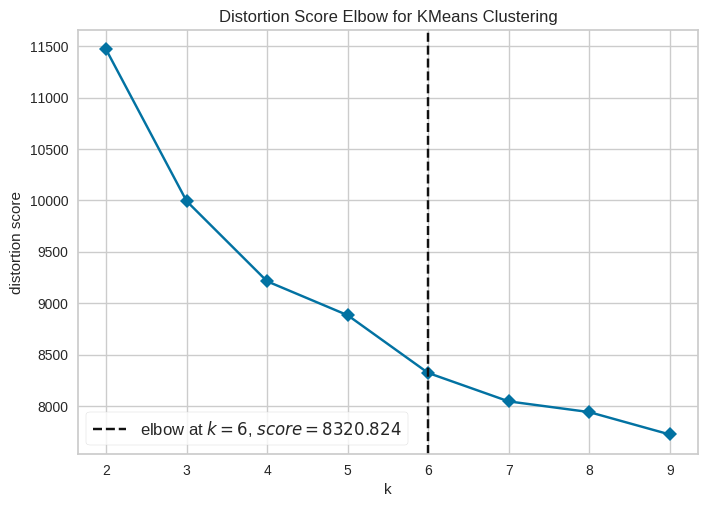


Jumlah cluster optimal (Elbow): 6


In [ ]:
# Melakukan visualisasi Elbow Method menggunakan KElbowVisualizer()
# Metode: KElbowVisualizer dari yellowbrick untuk menemukan k optimal
# Alasan: Elbow method membantu menentukan jumlah cluster optimal secara visual
#         berdasarkan penurunan distortion/inertia yang signifikan.

model_elbow = KMeans(random_state=42)
visualizer = KElbowVisualizer(model_elbow, k=(2, 10), timings=False)
visualizer.fit(df)
visualizer.show()

optimal_k = visualizer.elbow_value_
print(f'\nJumlah cluster optimal (Elbow): {optimal_k}')

In [ ]:
# Menggunakan algoritma K-Means Clustering
# Metode: sklearn.cluster.KMeans
# Alasan: K-Means adalah algoritma clustering yang efisien dan mudah diinterpretasikan
#         untuk mengelompokkan transaksi berdasarkan pola perilaku.

# Gunakan optimal_k dari elbow, atau 3 sebagai default jika elbow tidak terdeteksi
n_clusters = optimal_k if optimal_k is not None else 3
print(f'Menggunakan {n_clusters} cluster untuk K-Means')

model_clustering = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
model_clustering.fit(df)

# Tambahkan kolom hasil clustering ke dataframe (sementara)
df['Target'] = model_clustering.labels_
print(f'\nDistribusi cluster:')
print(df['Target'].value_counts().sort_index())

Menggunakan 6 cluster untuk K-Means

Distribusi cluster:
Target
0    169
1    407
2    120
3    303
4    201
5    269
Name: count, dtype: int64


In [ ]:
# Menyimpan model menggunakan joblib
joblib.dump(model_clustering, 'model_clustering.h5')
print('Model clustering berhasil disimpan sebagai model_clustering.h5')

Model clustering berhasil disimpan sebagai model_clustering.h5


## **Penilaian (Opsional) - Skilled: Silhouette Score dan Visualisasi Clustering**

In [ ]:
# Menghitung dan menampilkan nilai Silhouette Score
# Metode: silhouette_score dari sklearn.metrics
# Alasan: Silhouette Score mengukur seberapa baik setiap titik data cocok dengan
#         clusternya dibandingkan cluster lain. Nilai mendekati 1 = cluster baik.

X_cluster = df.drop(columns=['Target'])
sil_score = silhouette_score(X_cluster, df['Target'])
print(f'Silhouette Score (K-Means, k={n_clusters}): {sil_score:.4f}')

if sil_score >= 0.7:
    print('Interpretasi: Struktur cluster sangat kuat')
elif sil_score >= 0.5:
    print('Interpretasi: Struktur cluster cukup baik')
elif sil_score >= 0.25:
    print('Interpretasi: Struktur cluster lemah, mungkin perlu dicoba k berbeda')
else:
    print('Interpretasi: Tidak ada struktur cluster yang signifikan')

Silhouette Score (K-Means, k=6): 0.1668
Interpretasi: Tidak ada struktur cluster yang signifikan


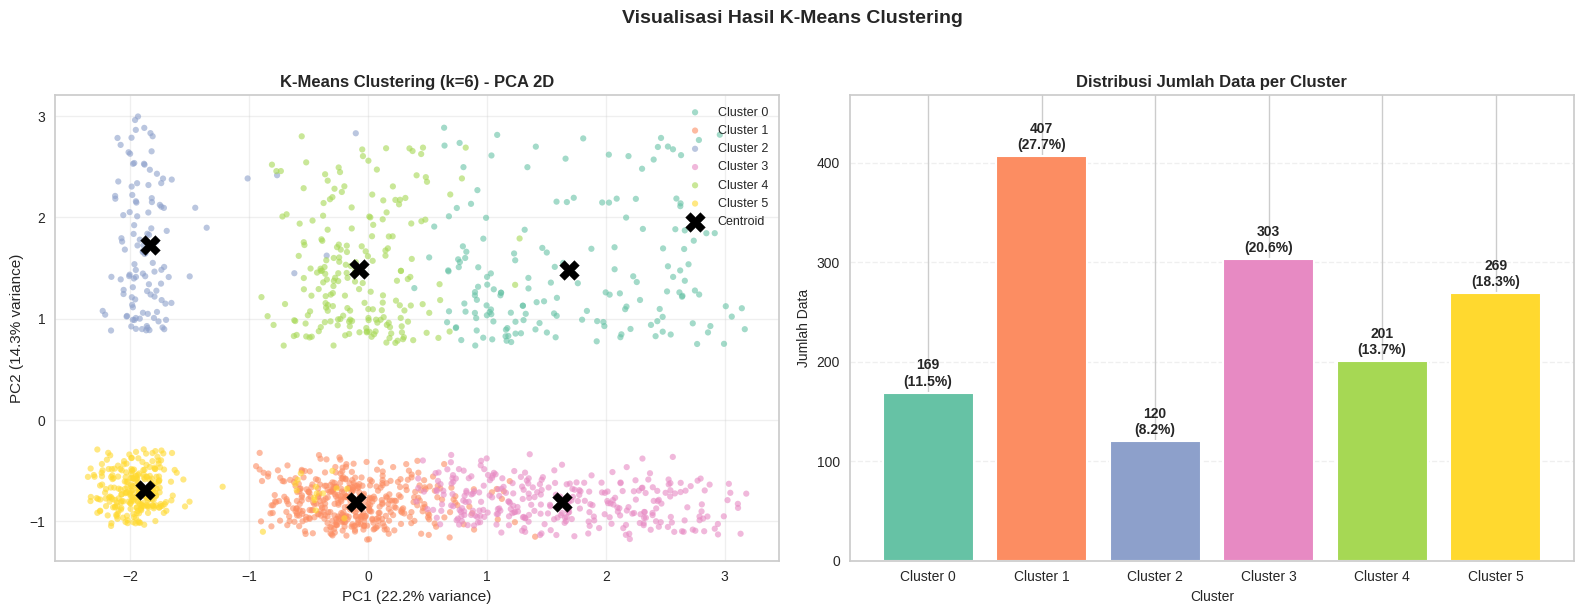

In [ ]:
# Membuat visualisasi hasil clustering menggunakan PCA 2D
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_cluster)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Scatter plot hasil clustering
colors = sns.color_palette('Set2', n_clusters)
for cluster_id in range(n_clusters):
    mask = df['Target'] == cluster_id
    axes[0].scatter(
        X_pca_2d[mask, 0],
        X_pca_2d[mask, 1],
        c=[colors[cluster_id]],
        label=f'Cluster {cluster_id}',
        alpha=0.6,
        s=20,
        edgecolors='none'
    )

# Plot centroid
centers_pca = pca_2d.transform(model_clustering.cluster_centers_)
axes[0].scatter(
    centers_pca[:, 0], centers_pca[:, 1],
    c='black', marker='X', s=200, zorder=5, label='Centroid'
)
axes[0].set_title(f'K-Means Clustering (k={n_clusters}) - PCA 2D', fontsize=12, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)')
axes[0].set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)')
axes[0].legend(loc='best', fontsize=9)
axes[0].grid(alpha=0.3)

# Plot 2: Distribusi cluster (bar chart)
cluster_counts = df['Target'].value_counts().sort_index()
bars = axes[1].bar(
    [f'Cluster {i}' for i in cluster_counts.index],
    cluster_counts.values,
    color=colors[:n_clusters],
    edgecolor='white',
    linewidth=1.5
)
for bar, val in zip(bars, cluster_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + max(cluster_counts.values)*0.01,
        f'{val:,}\n({val/len(df)*100:.1f}%)',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )
axes[1].set_title('Distribusi Jumlah Data per Cluster', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Cluster', fontsize=10)
axes[1].set_ylabel('Jumlah Data', fontsize=10)
axes[1].grid(axis='y', alpha=0.3, linestyle='--')
axes[1].set_ylim(0, max(cluster_counts.values) * 1.15)

plt.suptitle('Visualisasi Hasil K-Means Clustering', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## **Penilaian (Opsional) - Advanced: Model PCA untuk Clustering**

Jumlah komponen PCA untuk 90% explained variance: 8


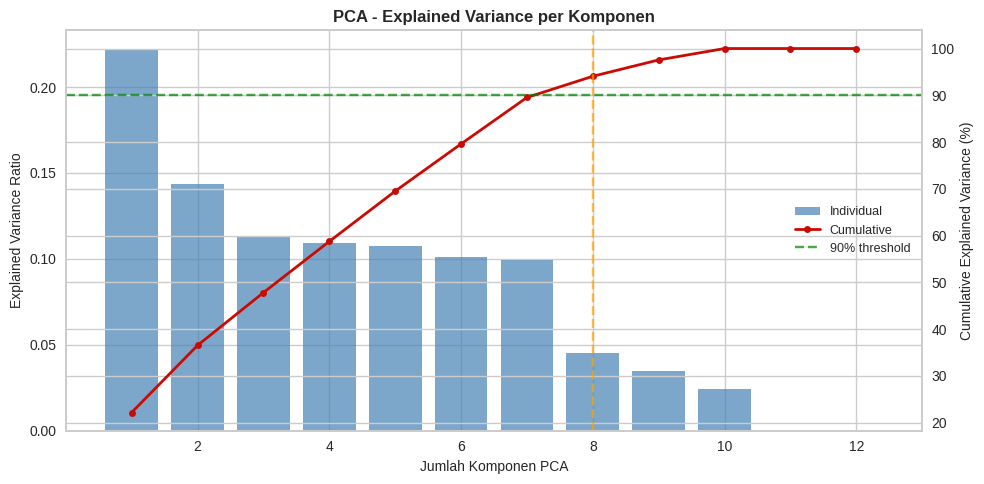

Silhouette Score PCA K-Means: 0.1820
Silhouette Score original K-Means: 0.1668
Model terbaik: PCA K-Means


In [ ]:
# Membangun model menggunakan PCA
# Metode: PCA untuk reduksi dimensi, lalu K-Means pada komponen utama
# Alasan: PCA membantu mengurangi noise dan multikolinearitas, sehingga
#         clustering menjadi lebih efisien dan akurat pada data berdimensi tinggi.

# Tentukan jumlah komponen PCA (variance explained >= 90%)
pca_full = PCA(random_state=42)
pca_full.fit(X_cluster)

cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_components = np.argmax(cumvar >= 0.90) + 1
print(f'Jumlah komponen PCA untuk 90% explained variance: {n_components}')

# Plot explained variance
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(1, len(pca_full.explained_variance_ratio_)+1),
       pca_full.explained_variance_ratio_,
       color='steelblue', alpha=0.7, label='Individual')
ax2 = ax.twinx()
ax2.plot(range(1, len(cumvar)+1), cumvar*100, 'r-o',
         markersize=5, linewidth=2, label='Cumulative')
ax2.axhline(y=90, color='green', linestyle='--', alpha=0.7, label='90% threshold')
ax2.axvline(x=n_components, color='orange', linestyle='--', alpha=0.7)
ax.set_xlabel('Jumlah Komponen PCA', fontsize=10)
ax.set_ylabel('Explained Variance Ratio', fontsize=10)
ax2.set_ylabel('Cumulative Explained Variance (%)', fontsize=10)
ax.set_title('PCA - Explained Variance per Komponen', fontsize=12, fontweight='bold')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='center right', fontsize=9)
plt.tight_layout()
plt.show()

# Fit PCA dengan n_components optimal
pca_model = PCA(n_components=n_components, random_state=42)
X_pca = pca_model.fit_transform(X_cluster)

# K-Means pada data PCA
kmeans_pca = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans_pca.fit(X_pca)

sil_pca = silhouette_score(X_pca, kmeans_pca.labels_)
print(f'Silhouette Score PCA K-Means: {sil_pca:.4f}')
print(f'Silhouette Score original K-Means: {sil_score:.4f}')
print(f'Model terbaik: {"PCA K-Means" if sil_pca > sil_score else "Original K-Means"}')

In [ ]:
# Simpan model PCA sebagai perbandingan
joblib.dump(pca_model, 'PCA_model_clustering.h5')
print('Model PCA berhasil disimpan sebagai PCA_model_clustering.h5')

Model PCA berhasil disimpan sebagai PCA_model_clustering.h5


# **5. Interpretasi Hasil Clustering**
Analisis karakteristik tiap cluster berdasarkan statistik deskriptif (mean, min, max) untuk fitur numerik.

In [ ]:
# Menampilkan analisis deskriptif minimal mean, min dan max untuk fitur numerik
# Pastikan nama kolom clustering sudah diubah menjadi Target
print('=== Analisis Deskriptif per Cluster (Data Setelah Preprocessing) ===')
print(f'Kolom Target (cluster) sudah ada: {"Target" in df.columns}')
print()

numeric_feat = [c for c in df.select_dtypes(include=[np.number]).columns if c != 'Target']

cluster_stats = df.groupby('Target')[numeric_feat].agg(['mean', 'min', 'max'])
print('Statistik deskriptif fitur numerik per cluster (mean, min, max):')
cluster_stats.round(3)

=== Analisis Deskriptif per Cluster (Data Setelah Preprocessing) ===
Kolom Target (cluster) sudah ada: True

Statistik deskriptif fitur numerik per cluster (mean, min, max):


TransactionAmount               TransactionType           Location  \
                    mean    min    max            mean  min  max     mean   
Target                                                                      
0                  1.135  0.269  2.805             0.0  0.0  0.0   -0.050   
1                 -0.605 -1.204  0.259             0.0  0.0  0.0   -0.014   
2                  1.328  0.278  2.802             0.0  0.0  0.0   -0.037   
3                 -0.612 -1.207  0.266             0.0  0.0  0.0    0.046   
4                  1.158  0.274  2.783             0.0  0.0  0.0    0.064   
5                 -0.565 -1.207  0.267             0.0  0.0  0.0   -0.031   

                     IP Address  ... LoginAttempts AccountBalance         \
          min    max       mean  ...           max           mean    min   
Target                           ...                                       
0      -1.718  1.695     -0.023  ...           0.0          1.180  0.427   
1      -1.718  1.695     -0.027  ...           0.0         -0.320 -1.281   
2      -1.718  1.695      0.116  ...           0.0         -0.950 -1.279   
3      -1.718  1.695     -0.006  ...           0.0          1.190  0.434   
4      -1.718  1.695     -0.089  ...           0.0         -0.349 -1.275   
5      -1.718  1.695      0.077  ...           0.0         -0.913 -1.278   

              TransactionAmount_bin         AccountBalance_bin          
          max                  mean min max               mean min max  
Target                                                                  
0       2.565                 0.000   0   0              0.000   0   0  
1       0.426                 1.486   1   2              1.791   1   2  
2       1.156                 0.000   0   0              1.008   0   2  
3       2.556                 1.495   1   2              0.000   0   0  
4       0.411                 0.000   0   0              1.761   1   2  
5       1.204                 1.524   1   2              0.981   0   2  

[6 rows x 36 columns]

In [ ]:
# Simpan Data Clustering
df_clustering = df.copy()
df_clustering.to_csv('data_clustering.csv', index=False)
print('Data clustering berhasil disimpan sebagai data_clustering.csv')
print(f'Shape: {df_clustering.shape}')
print(f'Kolom: {df_clustering.columns.tolist()}')

Data clustering berhasil disimpan sebagai data_clustering.csv
Shape: (1469, 13)
Kolom: ['TransactionAmount', 'TransactionType', 'Location', 'IP Address', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'TransactionAmount_bin', 'AccountBalance_bin', 'Target']


## **Penilaian (Opsional) - Skilled: Inverse Transform**

In [ ]:
# Mengembalikan data yang telah di-encode dan di-scale menggunakan inverse_transform()
# Metode: inverse_transform dari StandardScaler dan LabelEncoder
# Alasan: Mengembalikan data ke nilai asli memudahkan interpretasi bisnis yang bermakna.

df_inverse = df.copy()

# inverse scaling untuk fitur numerik (semua kecuali kolom bin dan Target)
scale_cols = [c for c in numeric_feat
              if '_bin' not in c and c in scaler.feature_names_in_]

print(f'Kolom yang di-inverse scale: {scale_cols}')
df_inverse[scale_cols] = scaler.inverse_transform(df_inverse[scale_cols])

# inverse encoding untuk fitur kategorikal asli
for col, le in label_encoders.items():
    if col in df_inverse.columns:
        try:
            df_inverse[col] = le.inverse_transform(df_inverse[col].astype(int))
        except Exception as e:
            print(f'  Catatan: inverse_transform untuk {col} dilewati - {e}')

print('\nData setelah inverse transform:')
df_inverse.head()

Kolom yang di-inverse scale: ['TransactionAmount', 'TransactionType', 'Location', 'IP Address', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']

Data setelah inverse transform:


,TransactionAmount,TransactionType,Location,IP Address,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionAmount_bin,AccountBalance_bin,Target
0,14.09,Debit,San Diego,162.198.218.92,ATM,70.0,Doctor,81.0,1.0,5112.21,Low,Medium,1
1,376.24,Debit,Houston,13.149.61.4,ATM,68.0,Doctor,141.0,1.0,13758.91,High,High,0
2,126.29,Debit,Mesa,215.97.143.157,Online,19.0,Student,56.0,1.0,1122.35,Medium,Low,5
3,184.50,Debit,Raleigh,200.13.225.150,Online,26.0,Student,25.0,1.0,8569.06,Medium,High,5
4,92.15,Debit,Oklahoma City,117.67.192.211,ATM,18.0,Student,172.0,1.0,781.68,Low,Low,5


In [ ]:
# Lakukan analisis deskriptif menggunakan data yang sudah di-inverse
print('=== Analisis Deskriptif per Cluster (Data Setelah Inverse Transform) ===')
print()

# Fitur Numerik
numeric_inverse = df_inverse.select_dtypes(include=[np.number]).columns.tolist()
numeric_inverse = [c for c in numeric_inverse if c != 'Target']

print('--- Fitur Numerik (mean, min, max, std) ---')
df_inverse.groupby('Target')[numeric_inverse].agg(['mean', 'min', 'max', 'std']).round(2)

=== Analisis Deskriptif per Cluster (Data Setelah Inverse Transform) ===

--- Fitur Numerik (mean, min, max, std) ---


TransactionAmount                         CustomerAge              \
                    mean     min     max     std        mean   min   max   
Target                                                                     
0                 463.21  292.08  793.13  143.38       51.03  26.0  80.0   
1                 119.19    0.84  290.02   82.63       54.22  26.0  80.0   
2                 501.17  293.85  792.57  146.39       23.07  18.0  28.0   
3                 117.88    0.32  291.46   82.72       49.74  26.0  78.0   
4                 467.63  292.95  788.84  137.01       52.79  26.0  80.0   
5                 127.10    0.26  291.68   83.40       23.17  18.0  28.0   

              TransactionDuration                     LoginAttempts            \
          std                mean   min    max    std          mean  min  max   
Target                                                                          
0       14.02              117.50  11.0  296.0  68.57           1.0  1.0  1.0   
1       14.57              117.62  11.0  298.0  69.59           1.0  1.0  1.0   
2        3.04              126.72  14.0  291.0  72.63           1.0  1.0  1.0   
3       13.64              121.38  10.0  300.0  74.17           1.0  1.0  1.0   
4       13.85              116.90  10.0  285.0  68.00           1.0  1.0  1.0   
5        3.23              118.17  13.0  299.0  74.00           1.0  1.0  1.0   

            AccountBalance                              
        std           mean      min       max      std  
Target                                                  
0       0.0        9625.65  6712.94  14977.99  2365.71  
1       0.0        3827.32   112.76   6711.15  1894.21  
2       0.0        1392.00   117.98   9532.42  1587.97  
3       0.0        9662.98  6741.41  14942.78  2372.88  
4       0.0        3712.54   135.96   6651.62  1913.88  
5       0.0        1533.58   123.24   9716.68  1868.35

In [ ]:
# Analisis fitur kategorikal
cat_inverse = df_inverse.select_dtypes(include=['object']).columns.tolist()
print('--- Fitur Kategorikal (mode/frekuensi) ---')

for col in cat_inverse:
    print(f'\n[{col}]')
    cat_stats = df_inverse.groupby('Target')[col].agg(
        lambda x: x.value_counts().index[0]
    ).rename('Mode')
    cat_pct = df_inverse.groupby(['Target', col]).size().unstack(fill_value=0)
    cat_pct_norm = cat_pct.div(cat_pct.sum(axis=1), axis=0).round(3) * 100
    print(f'  Mode per cluster: {cat_stats.to_dict()}')
    print(f'  Distribusi (%):')
    print(cat_pct_norm.to_string())

--- Fitur Kategorikal (mode/frekuensi) ---

[TransactionType]
  Mode per cluster: {0: 'Debit', 1: 'Debit', 2: 'Debit', 3: 'Debit', 4: 'Debit', 5: 'Debit'}
  Distribusi (%):
TransactionType  Debit
Target                
0                100.0
1                100.0
2                100.0
3                100.0
4                100.0
5                100.0

[Location]
  Mode per cluster: {0: 'Fort Worth', 1: 'Chicago', 2: 'Los Angeles', 3: 'San Jose', 4: 'Milwaukee', 5: 'Chicago'}
  Distribusi (%):
Location  Albuquerque  Atlanta  Austin  Baltimore  Boston  Charlotte  Chicago  Columbus  Dallas  Denver  Detroit  El Paso  Fort Worth  Fresno  Houston  Indianapolis  Jacksonville  Kansas City  Las Vegas  Los Angeles  Louisville  Memphis  Mesa  Miami  Milwaukee  Nashville  New York  Oklahoma City  Omaha  Philadelphia  Phoenix  Portland  Raleigh  Sacramento  San Antonio  San Diego  San Francisco  San Jose  Seattle  Tucson  Virginia Beach  Washington
Target                                        

In [ ]:
# Menjelaskan karakteristik tiap cluster berdasarkan hasil agregasi

print('=== INTERPRETASI KARAKTERISTIK CLUSTER ===')
print()

cluster_summary = df_inverse.groupby('Target')[numeric_inverse].mean().round(2)

for cluster_id in sorted(df_inverse['Target'].unique()):
    subset = cluster_summary.loc[cluster_id]
    n_data = (df_inverse['Target'] == cluster_id).sum()
    pct = n_data / len(df_inverse) * 100
    print(f'--- Cluster {cluster_id} ({n_data} data, {pct:.1f}%) ---')
    for feat in numeric_inverse:
        global_mean = df_inverse[feat].mean()
        cluster_val = subset[feat]
        level = 'TINGGI' if cluster_val > global_mean * 1.1 else ('RENDAH' if cluster_val < global_mean * 0.9 else 'SEDANG')
        print(f'  {feat}: {cluster_val:.2f} ({level} vs rata-rata global {global_mean:.2f})')
    print()

=== INTERPRETASI KARAKTERISTIK CLUSTER ===

--- Cluster 0 (169 data, 11.5%) ---
  TransactionAmount: 463.21 (TINGGI vs rata-rata global 238.83)
  CustomerAge: 51.03 (TINGGI vs rata-rata global 44.50)
  TransactionDuration: 117.50 (SEDANG vs rata-rata global 119.13)
  LoginAttempts: 1.00 (SEDANG vs rata-rata global 1.00)
  AccountBalance: 9625.65 (TINGGI vs rata-rata global 5063.40)

--- Cluster 1 (407 data, 27.7%) ---
  TransactionAmount: 119.19 (RENDAH vs rata-rata global 238.83)
  CustomerAge: 54.22 (TINGGI vs rata-rata global 44.50)
  TransactionDuration: 117.62 (SEDANG vs rata-rata global 119.13)
  LoginAttempts: 1.00 (SEDANG vs rata-rata global 1.00)
  AccountBalance: 3827.32 (RENDAH vs rata-rata global 5063.40)

--- Cluster 2 (120 data, 8.2%) ---
  TransactionAmount: 501.17 (TINGGI vs rata-rata global 238.83)
  CustomerAge: 23.07 (RENDAH vs rata-rata global 44.50)
  TransactionDuration: 126.72 (SEDANG vs rata-rata global 119.13)
  LoginAttempts: 1.00 (SEDANG vs rata-rata global 1

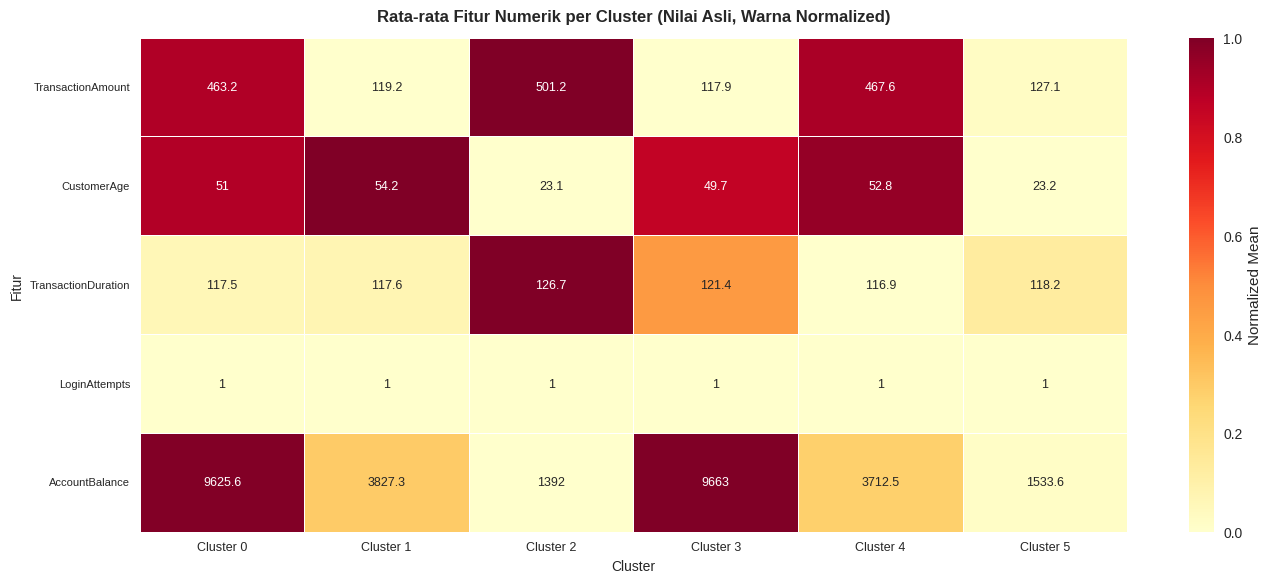

In [ ]:
# Visualisasi karakteristik cluster
fig, ax = plt.subplots(figsize=(14, 6))

# Heatmap rata-rata fitur numerik per cluster (normalized)
cluster_means = df_inverse.groupby('Target')[numeric_inverse].mean()
cluster_means_norm = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min() + 1e-8)

sns.heatmap(
    cluster_means_norm.T,
    annot=cluster_means.T.round(1),
    fmt='g',
    cmap='YlOrRd',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Normalized Mean'},
    annot_kws={'size': 9}
)
ax.set_title('Rata-rata Fitur Numerik per Cluster (Nilai Asli, Warna Normalized)',
             fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Cluster', fontsize=10)
ax.set_ylabel('Fitur', fontsize=10)
ax.set_xticklabels([f'Cluster {i}' for i in cluster_means.index], fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=8, rotation=0)
plt.tight_layout()
plt.show()

## **Penilaian (Opsional) - Advanced: Integrasi Data Inverse + Simpan CSV**

In [ ]:
# Periksa kembali data yang telah di-inverse
print('=== Pemeriksaan Data Inverse ===')
print(f'Shape: {df_inverse.shape}')
print(f'Kolom: {df_inverse.columns.tolist()}')
print(f'Tipe data:')
print(df_inverse.dtypes)
print()
print('5 baris pertama:')
df_inverse.head()

=== Pemeriksaan Data Inverse ===
Shape: (1469, 13)
Kolom: ['TransactionAmount', 'TransactionType', 'Location', 'IP Address', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'TransactionAmount_bin', 'AccountBalance_bin', 'Target']
Tipe data:
TransactionAmount        float64
TransactionType           object
Location                  object
IP Address                object
Channel                   object
CustomerAge              float64
CustomerOccupation        object
TransactionDuration      float64
LoginAttempts            float64
AccountBalance           float64
TransactionAmount_bin     object
AccountBalance_bin        object
Target                     int32
dtype: object

5 baris pertama:


,TransactionAmount,TransactionType,Location,IP Address,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionAmount_bin,AccountBalance_bin,Target
0,14.09,Debit,San Diego,162.198.218.92,ATM,70.0,Doctor,81.0,1.0,5112.21,Low,Medium,1
1,376.24,Debit,Houston,13.149.61.4,ATM,68.0,Doctor,141.0,1.0,13758.91,High,High,0
2,126.29,Debit,Mesa,215.97.143.157,Online,19.0,Student,56.0,1.0,1122.35,Medium,Low,5
3,184.50,Debit,Raleigh,200.13.225.150,Online,26.0,Student,25.0,1.0,8569.06,Medium,High,5
4,92.15,Debit,Oklahoma City,117.67.192.211,ATM,18.0,Student,172.0,1.0,781.68,Low,Low,5


In [ ]:
# Simpan Data Inverse
# Mengintegrasikan data yang telah di-inverse dengan hasil cluster (kolom Target)
df_inverse.to_csv('data_clustering_inverse.csv', index=False)
print('Data clustering inverse berhasil disimpan sebagai data_clustering_inverse.csv')
print(f'Shape: {df_inverse.shape}')
print(f'Kolom Target ada: {"Target" in df_inverse.columns}')
print(f'\nDistribusi Target:')
print(df_inverse['Target'].value_counts().sort_index())

Data clustering inverse berhasil disimpan sebagai data_clustering_inverse.csv
Shape: (1469, 13)
Kolom Target ada: True

Distribusi Target:
Target
0    169
1    407
2    120
3    303
4    201
5    269
Name: count, dtype: int64


# **End of Clustering Notebook**